In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.0.2
Pandas: 2.3.3
Scikit-learn: 1.6.1


In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer

import string
import re

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn import metrics

from time import time

In [4]:
import os

os.makedirs("DATAPATH", exist_ok=True)

!wget -P DATAPATH https://raw.githubusercontent.com/practical-nlp/practical-nlp/master/Ch4/Data/Full-Economic-News-DFE-839861.csv

!ls -lah DATAPATH

our_data = pd.read_csv(
    "DATAPATH/Full-Economic-News-DFE-839861.csv",
    encoding="ISO-8859-1"
)

--2026-09-26 02:51:05--  https://raw.githubusercontent.com/practical-nlp/practical-nlp/master/Ch4/Data/Full-Economic-News-DFE-839861.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12383529 (12M) [application/octet-stream]
Saving to: ‘DATAPATH/Full-Economic-News-DFE-839861.csv’

Full-Economic-News- 100%[===================>]  11.81M  48.5MB/s    in 0.2s    

2026-09-26 02:51:05 (48.5 MB/s) - ‘DATAPATH/Full-Economic-News-DFE-839861.csv’ saved [12383529/12383529]

total 12M
drwxr-xr-x 2 root root 4.0K Sep 26 02:51 .
drwxr-xr-x 3 root root 4.0K Sep 26 02:51 ..
-rw-r--r-- 1 root root  12M Sep 26 02:51 Full-Economic-News-DFE-839861.csv


In [5]:
display(our_data.shape)  # Number of rows (instances) and columns in the dataset

our_data["relevance"].value_counts() / our_data.shape[0] 

(8000, 15)

relevance
no          0.821375
yes         0.177500
not sure    0.001125
Name: count, dtype: float64

In [6]:
our_data = our_data[our_data.relevance != "not sure"] # removing the data where we don't want relevance="not sure".
our_data.shape
our_data['relevance'] = our_data.relevance.map({'yes':1, 'no':0}) # relevant is 1, not-relevant is 0. 
our_data = our_data[["text","relevance"]] # Let us take only the two columns we need.
our_data.shape

(7991, 2)

In [7]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stopwords = ENGLISH_STOP_WORDS

def clean(doc):  # doc is a string of text
    doc = doc.replace("</br>", " ")
    doc = "".join([
        char for char in doc
        if char not in string.punctuation and not char.isdigit()
    ])
    doc = " ".join([
        token for token in doc.split()
        if token.lower() not in stopwords
    ])
    return doc

In [8]:
import sklearn
#from sklearn.cross_validation import train_test_split
from sklearn.model_selection import train_test_split

# Step 1: train-test split
X = our_data.text
y = our_data.relevance

print(X.shape, y.shape)

# Split X dan y menjadi data training dan testing
# 75% training dan 25% testing
# random_state=1 untuk hasil yang konsisten
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=1
)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(7991,) (7991,)
(5993,) (5993,)
(1998,) (1998,)


In [9]:
# Step 2-3: Preprocess and Vectorize train and test data
vect = CountVectorizer(preprocessor=clean) # instantiate a vectoriezer
X_train_dtm = vect.fit_transform(X_train)# use it to extract features from training data
# transform testing data (using training data's features)
X_test_dtm = vect.transform(X_test)
print(X_train_dtm.shape, X_test_dtm.shape)
# i.e., the dimension of our feature vector is 49753!

(5993, 49435) (1998, 49435)


In [10]:
# Step 3: Train the classifier and predict for test data
nb = MultinomialNB() # instantiate a Multinomial Naive Bayes model
%time nb.fit(X_train_dtm, y_train) # train the model(timing it with an IPython "magic command")
y_pred_class = nb.predict(X_test_dtm)

CPU times: user 8.78 ms, sys: 974 µs, total: 9.75 ms
Wall time: 10.3 ms


Accuracy:  0.7817817817817818


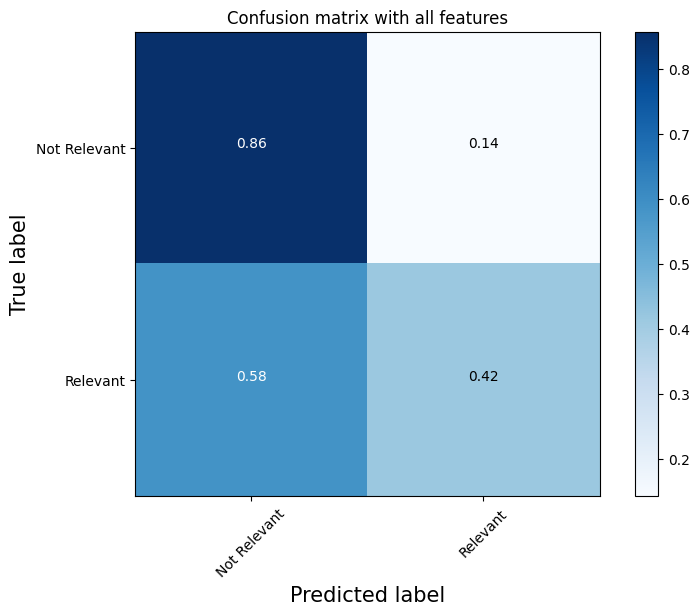

ROC_AUC_Score:  0.7242174478063113


In [11]:
# Step 4: Evaluate the classifier using various measures

# Function to plot confusion matrix
import itertools
from sklearn.metrics import roc_auc_score

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.

    for i, j in itertools.product(
        range(cm.shape[0]),
        range(cm.shape[1])
        ):
        plt.text(
            j, i, format(cm[i, j], fmt),
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black"
        )

    plt.tight_layout()
    plt.ylabel('True label', fontsize=15)
    plt.xlabel('Predicted label', fontsize=15)


# Print accuracy
print("Accuracy: ", accuracy_score(y_test, y_pred_class))


# Print the confusion matrix
cnf_matrix = confusion_matrix(y_test, y_pred_class)

plt.figure(figsize=(8, 6))

plot_confusion_matrix(
    cnf_matrix,
    classes=['Not Relevant', 'Relevant'],
    normalize=True,
    title='Confusion matrix with all features'
)

plt.show()


# Calculate AUC (Area Under the Curve)
y_pred_prob = nb.predict_proba(X_test_dtm)[:, 1]

print("ROC_AUC_Score: ", roc_auc_score(y_test, y_pred_prob))

CPU times: user 4.89 ms, sys: 0 ns, total: 4.89 ms
Wall time: 4.91 ms
Accuracy:  0.6881881881881882


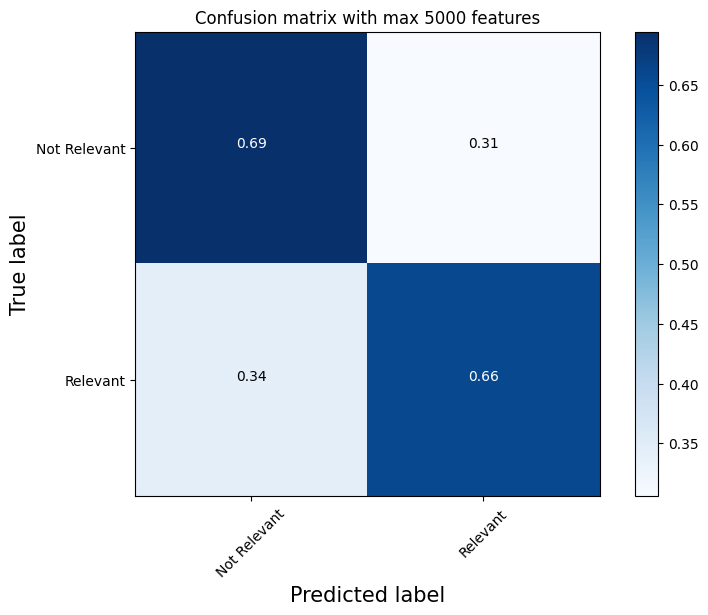

In [12]:
vect = CountVectorizer(
    preprocessor=clean,
    max_features=5000
)  # Step-1

X_train_dtm = vect.fit_transform(X_train)  # combined step 2 and 3
X_test_dtm = vect.transform(X_test)

nb = MultinomialNB()  # instantiate a Multinomial Naive Bayes model

%time nb.fit(X_train_dtm, y_train)  # train the model

y_pred_class = nb.predict(X_test_dtm)  # make class predictions

print("Accuracy: ", metrics.accuracy_score(y_test, y_pred_class))

# Print the confusion matrix
cnf_matrix = confusion_matrix(y_test, y_pred_class)

plt.figure(figsize=(8, 6))

plot_confusion_matrix(
    cnf_matrix,
    classes=['Not Relevant', 'Relevant'],
    normalize=True,
    title='Confusion matrix with max 5000 features'
)

plt.show()

Accuracy:  0.7352352352352353
AUC:  0.6544957906037234


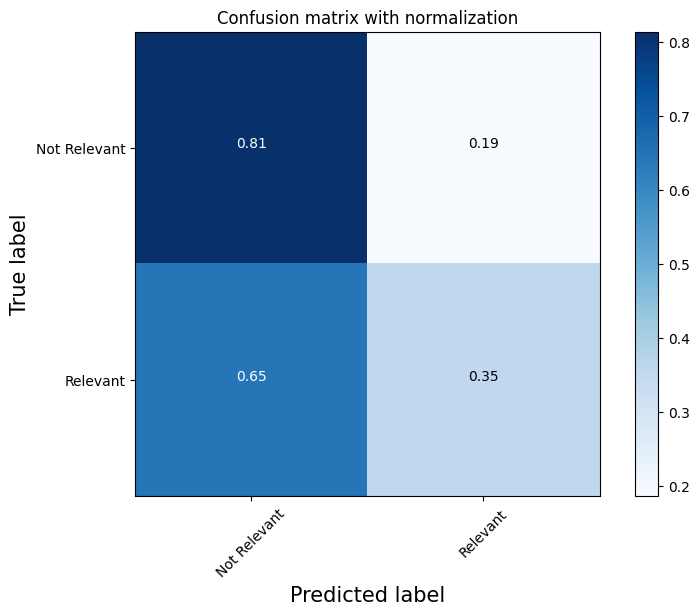

In [13]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(class_weight="balanced")

logreg.fit(X_train_dtm, y_train)

# Make predictions on test data
y_pred_class = logreg.predict(X_test_dtm)

# Probability for AUC
y_pred_prob = logreg.predict_proba(X_test_dtm)[:, 1]

# Calculate evaluation measures
print("Accuracy: ", accuracy_score(y_test, y_pred_class))
print("AUC: ", roc_auc_score(y_test, y_pred_prob))

cnf_matrix = confusion_matrix(y_test, y_pred_class)

plt.figure(figsize=(8, 6))

plot_confusion_matrix(
    cnf_matrix,
    classes=['Not Relevant', 'Relevant'],
    normalize=True,
    title='Confusion matrix with normalization'
)

plt.show()

Accuracy:  0.7337337337337337
AUC:  0.6256038647342994


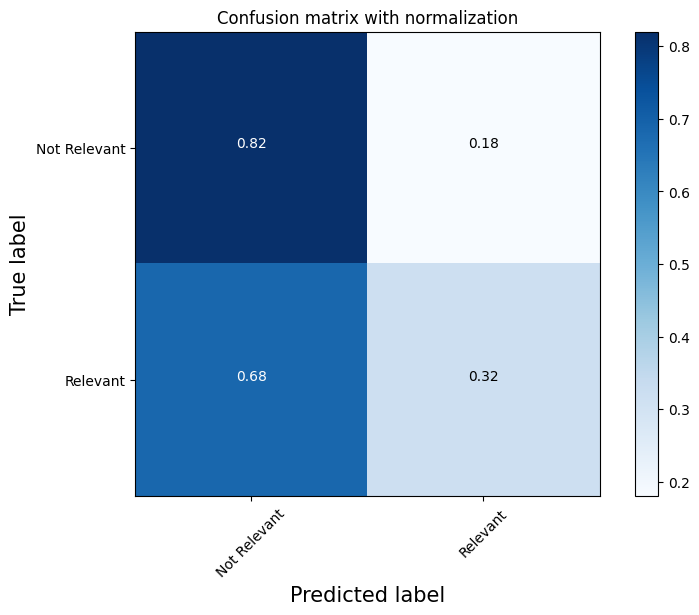

In [14]:
from sklearn.svm import LinearSVC

vect = CountVectorizer(
    preprocessor=clean,
    max_features=5000
)

X_train_dtm = vect.fit_transform(X_train)
X_test_dtm = vect.transform(X_test)

classifier = LinearSVC(class_weight='balanced')
classifier.fit(X_train_dtm, y_train)

# Make predictions on test data
y_pred_class = classifier.predict(X_test_dtm)

# Calculate evaluation measures
print("Accuracy: ", accuracy_score(y_test, y_pred_class))

# AUC menggunakan decision score dari LinearSVC
y_pred_score = classifier.decision_function(X_test_dtm)
print("AUC: ", roc_auc_score(y_test, y_pred_score))

cnf_matrix = confusion_matrix(y_test, y_pred_class)

plt.figure(figsize=(8, 6))

plot_confusion_matrix(
    cnf_matrix,
    classes=['Not Relevant', 'Relevant'],
    normalize=True,
    title='Confusion matrix with normalization'
)

plt.show()